In [5]:
!pip install pandas numpy matplotlib seaborn statsmodels openpyxl scikit-learn

MEMBACA DATA EXCEL

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

import warnings
warnings.filterwarnings("ignore")

file_path = "Data Pendukung BPHTB PAK 2026 dan Target 2027.xlsx"

df = pd.read_excel(file_path, header=None)

bulan = [
    "Januari", "Februari", "Maret", "April",
    "Mei", "Juni", "Juli", "Agustus",
    "September", "Oktober", "November", "Desember"
]

# Posisi kolom realisasi total berdasarkan struktur Excel
kolom_realisasi = {
    2021: 4,
    2022: 8,
    2023: 12,
    2024: 16,
    2025: 25,
    2026: 33
}

data = []

# Mengambil data Januari-Desember 2021-2025
for tahun in range(2021, 2026):
    kolom = kolom_realisasi[tahun]

    for i in range(12):
        nilai = pd.to_numeric(
            df.iloc[5 + i, kolom],
            errors="coerce"
        )

        data.append({
            "Tanggal": pd.Timestamp(tahun, i + 1, 1),
            "Realisasi": nilai
        })

# Mengambil data aktual Januari-Agustus 2026
for i in range(8):
    nilai = pd.to_numeric(
        df.iloc[5 + i, kolom_realisasi[2026]],
        errors="coerce"
    )

    data.append({
        "Tanggal": pd.Timestamp(2026, i + 1, 1),
        "Realisasi": nilai
    })

# Membentuk time series
data_ts = pd.DataFrame(data)

data_ts["Tanggal"] = pd.to_datetime(data_ts["Tanggal"])

data_ts = data_ts.sort_values("Tanggal")

data_ts = data_ts.set_index("Tanggal")

# Memastikan data lengkap
data_ts = data_ts.dropna()

y = data_ts["Realisasi"].astype(float)

print("Jumlah observasi:", len(y))
print("\nData historis:")
print(data_ts.tail(15))

print("\nStatistik deskriptif:")
print(data_ts.describe())

Jumlah observasi: 68

Data historis:
            Realisasi
Tanggal              
2025-06-01   1.050248
2025-07-01   0.533780
2025-08-01   0.877223
2025-09-01   0.512527
2025-10-01   0.537215
2025-11-01   1.423987
2025-12-01   1.435255
2026-01-01   0.946613
2026-02-01   0.711121
2026-03-01   0.654462
2026-04-01   0.934928
2026-05-01   0.764327
2026-06-01   0.958355
2026-07-01   1.021014
2026-08-01   0.528681

Statistik deskriptif:
          Realisasi
count  6.800000e+01
mean   7.835569e+10
std    7.082944e+10
min    5.125267e-01
25%    1.081658e+00
50%    8.300851e+10
75%    1.067963e+11
max    2.797364e+11


VISUALISASI DATA TIME SERIES

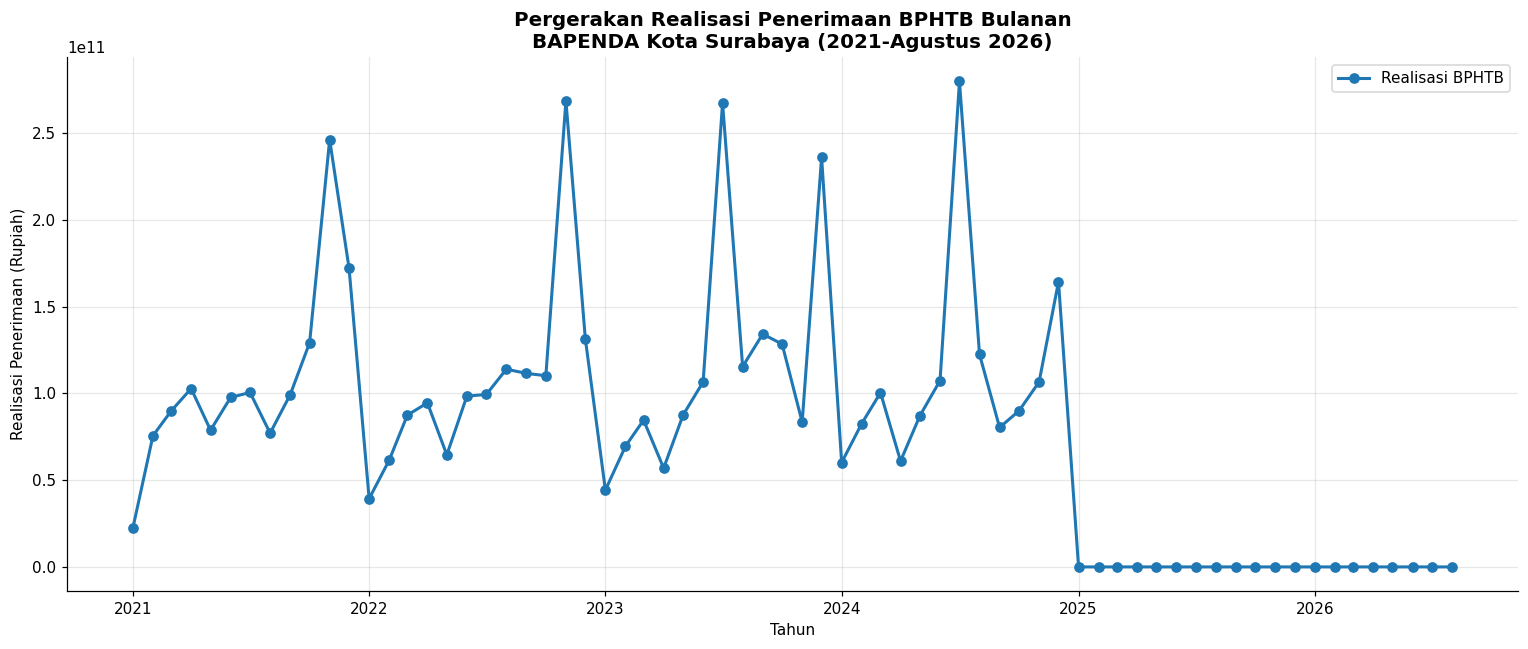

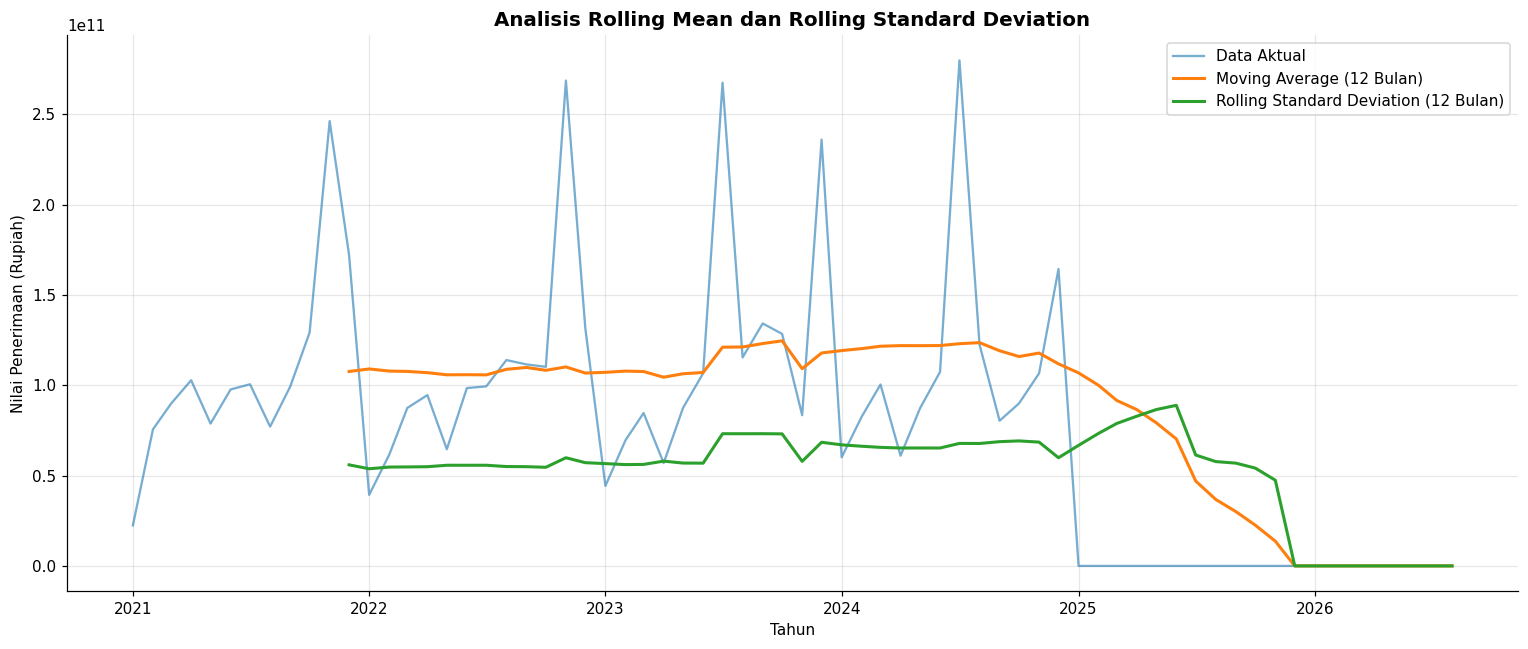

In [16]:
plt.figure(figsize=(14, 6))

plt.plot(
    y.index,
    y.values,
    marker="o",
    linewidth=2,
    label="Realisasi BPHTB"
)

plt.title(
    "Pergerakan Realisasi Penerimaan BPHTB Bulanan\n"
    "BAPENDA Kota Surabaya (2021-Agustus 2026)",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel("Tahun")
plt.ylabel("Realisasi Penerimaan (Rupiah)")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ROLLING MEAN DAN ROLLING STANDARD DEVIATION

rolling_mean = y.rolling(window=12).mean()
rolling_std = y.rolling(window=12).std()

plt.figure(figsize=(14, 6))

plt.plot(
    y,
    label="Data Aktual",
    alpha=0.6
)

plt.plot(
    rolling_mean,
    label="Moving Average (12 Bulan)",
    linewidth=2
)

plt.plot(
    rolling_std,
    label="Rolling Standard Deviation (12 Bulan)",
    linewidth=2
)

plt.title(
    "Analisis Rolling Mean dan Rolling Standard Deviation",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel("Tahun")
plt.ylabel("Nilai Penerimaan (Rupiah)")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

UJI STASIONERITAS ADF

In [24]:
def uji_adf(data, nama):

    hasil = adfuller(data.dropna(), autolag="AIC")

    print("UJI ADF:", nama)

    print("ADF Statistic :", hasil[0])
    print("P-Value       :", hasil[1])
    print("Critical Value:")

    for key, value in hasil[4].items():
        print(f"{key}: {value}")

    if hasil[1] < 0.05:
        print("Kesimpulan: Data STASIONER")
    else:
        print("Kesimpulan: Data TIDAK STASIONER")

    return hasil[1]


# Uji data asli
pvalue_asli = uji_adf(y, "Data Asli")

# Differencing pertama
y_diff = y.diff().dropna()

pvalue_diff = uji_adf(
    y_diff,
    "Differencing Pertama"
)

UJI ADF: Data Asli
ADF Statistic : -0.9048991763664705
P-Value       : 0.7863547672665874
Critical Value:
1%: -3.542412746661615
5%: -2.910236235808284
10%: -2.5927445767266866
Kesimpulan: Data TIDAK STASIONER
UJI ADF: Differencing Pertama
ADF Statistic : -5.2647468726864695
P-Value       : 6.475542757264888e-06
Critical Value:
1%: -3.542412746661615
5%: -2.910236235808284
10%: -2.5927445767266866
Kesimpulan: Data STASIONER


VISUALISASI DIFFERENCING

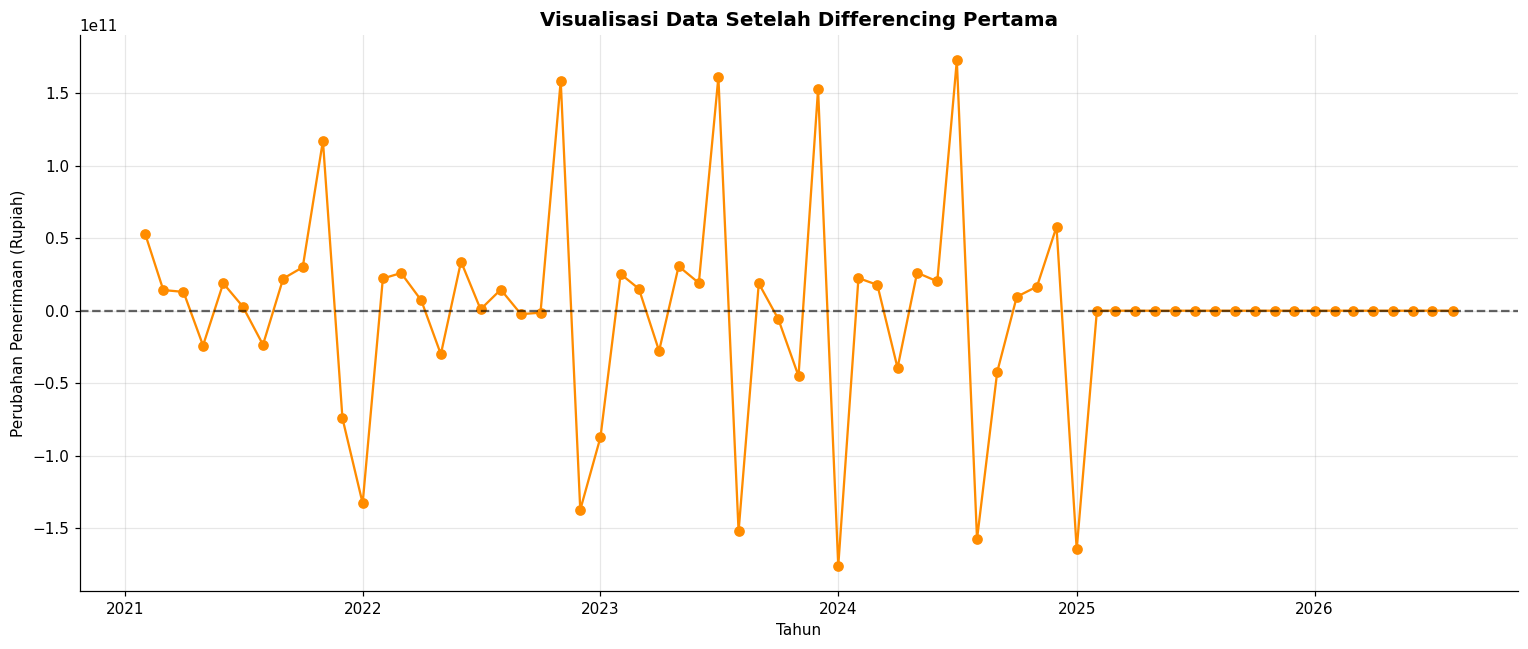

In [18]:
plt.figure(figsize=(14, 6))

plt.plot(
    y_diff,
    color="darkorange",
    marker="o",
    linewidth=1.5
)

plt.axhline(
    y=0,
    color="black",
    linestyle="--",
    alpha=0.6
)

plt.title(
    "Visualisasi Data Setelah Differencing Pertama",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel("Tahun")
plt.ylabel("Perubahan Penerimaan (Rupiah)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

MODEL REGARIMA

In [19]:
def buat_variabel_regresi(index, start=0):

    exog = pd.DataFrame(index=index)

    # Variabel tren
    exog["Trend"] = np.arange(
        start,
        start + len(index)
    )

    # Variabel dummy bulan
    dummy = pd.get_dummies(
        index.month,
        prefix="Bulan",
        drop_first=True,
        dtype=float
    )

    dummy.index = index

    exog = pd.concat(
        [exog, dummy],
        axis=1
    )

    return exog


# Variabel eksogen data historis
X_train = buat_variabel_regresi(y.index)

# Membangun model RegARIMA
model_regarima = SARIMAX(
    y,
    exog=X_train,
    order=(1, 1, 1),
    seasonal_order=(1, 0, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

hasil_regarima = model_regarima.fit(
    disp=False,
    maxiter=500
)

print(hasil_regarima.summary())

                                     SARIMAX Results                                      
Dep. Variable:                          Realisasi   No. Observations:                   68
Model:             SARIMAX(1, 1, 1)x(1, 0, 1, 12)   Log Likelihood               -1368.458
Date:                            Tue, 10 Nov 2026   AIC                           2770.916
Time:                                    02:28:23   BIC                           2804.410
Sample:                                01-01-2021   HQIC                          2783.796
                                     - 08-01-2026                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Trend      -1.104e+09   5.37e-11  -2.05e+19      0.000    -1.1e+09    -1.1e+09
Bulan_2     2.162e+10   1.95e-12   

MODEL HOLT-WINTERS

In [20]:
model_hw = ExponentialSmoothing(
    y,
    trend="add",
    seasonal="add",
    seasonal_periods=12,
    initialization_method="estimated"
)

hasil_hw = model_hw.fit(
    optimized=True
)

print(hasil_hw.summary())

                            ExponentialSmoothing Model Results                            
Dep. Variable:                Realisasi   No. Observations:                             68
Model:             ExponentialSmoothing   SSE                 136320051334932915552256.000
Optimized:                         True   AIC                                     3367.385
Trend:                         Additive   BIC                                     3402.897
Seasonal:                      Additive   AICC                                    3381.345
Seasonal Periods:                    12   Date:                           Tue, 10 Nov 2026
Box-Cox:                          False   Time:                                   02:28:41
Box-Cox Coeff.:                    None                                                   
                          coeff                 code              optimized      
---------------------------------------------------------------------------------
smoothing_level  

PERAMALAN REGARIMA DAN HOLT-WINTERS

In [25]:
periode_forecast = 16

future_index = pd.date_range(
    start=y.index[-1] + pd.DateOffset(months=1),
    periods=periode_forecast,
    freq="MS"
)

# Forecast RegARIMA

X_future = buat_variabel_regresi(
    future_index,
    start=len(y)
)

forecast_regarima = hasil_regarima.get_forecast(
    steps=periode_forecast,
    exog=X_future
)

pred_regarima = forecast_regarima.predicted_mean

interval_regarima = forecast_regarima.conf_int()


# Forecast Holt-Winters

pred_hw = hasil_hw.forecast(
    periode_forecast
)

pred_hw.index = future_index


# Tabel hasil peramalan

hasil_forecast = pd.DataFrame({
    "RegARIMA": pred_regarima,
    "Holt-Winters": pred_hw
})

hasil_forecast.index.name = "Tanggal"

hasil_forecast["Bulan"] = (
    hasil_forecast.index.strftime("%B %Y")
)

print("\nHASIL PERAMALAN BPHTB")
print(hasil_forecast)

hasil_forecast.to_excel(
    "Hasil_Peramalan_BPHTB_2026_2027.xlsx"
)


HASIL PERAMALAN BPHTB
                RegARIMA  Holt-Winters           Bulan
Tanggal                                               
2026-09-01 -1.203447e+10 -8.262870e+09  September 2026
2026-10-01 -1.000649e+10  1.433344e+09    October 2026
2026-11-01  7.749093e+09  6.456742e+10   November 2026
2026-12-01  3.778602e+10  6.574138e+10   December 2026
2027-01-01 -4.383356e+10 -7.233980e+10    January 2027
2027-02-01 -3.808473e+10 -5.338170e+10   February 2027
2027-03-01 -3.201032e+10 -3.728038e+10      March 2027
2027-04-01 -4.555111e+10 -5.020961e+10      April 2027
2027-05-01 -3.465101e+10 -4.007735e+10        May 2027
2027-06-01 -2.752198e+10 -1.787919e+10       June 2027
2027-07-01  3.394040e+10  6.520090e+10       July 2027
2027-08-01 -2.067071e+10 -1.336215e+10     August 2027
2027-09-01 -2.487985e+10 -1.295024e+10  September 2027
2027-10-01 -2.159278e+10 -3.254031e+09    October 2027
2027-11-01  4.690999e+09  5.988005e+10   November 2027
2027-12-01  2.658160e+10  6.105401e+10   D

VISUALISASI PERBANDINGAN MODEL

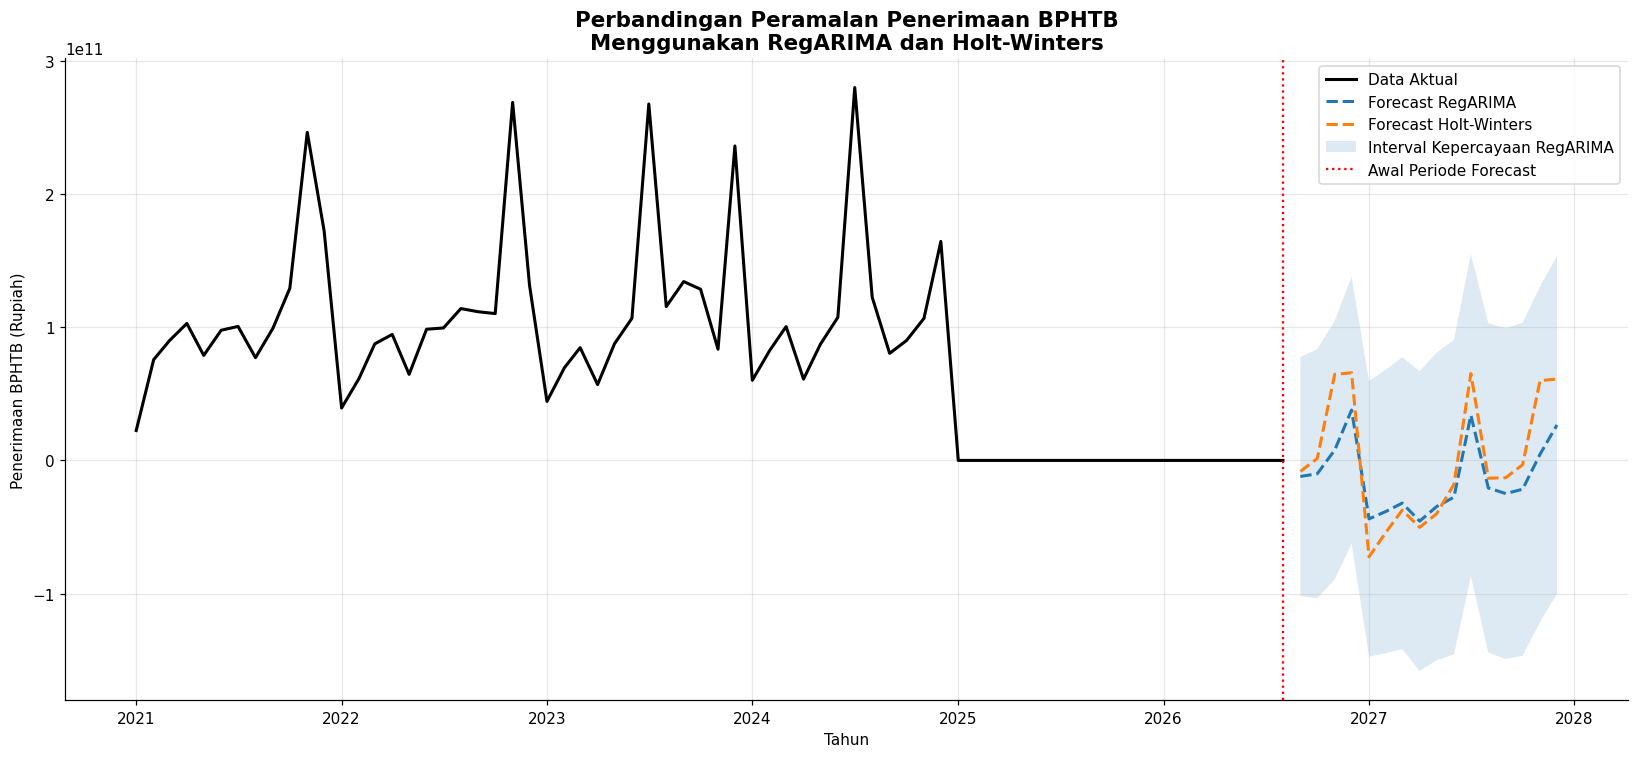

In [22]:
plt.figure(figsize=(15, 7))

plt.plot(
    y.index,
    y.values,
    label="Data Aktual",
    color="black",
    linewidth=2
)

plt.plot(
    pred_regarima.index,
    pred_regarima.values,
    label="Forecast RegARIMA",
    linestyle="--",
    linewidth=2
)

plt.plot(
    pred_hw.index,
    pred_hw.values,
    label="Forecast Holt-Winters",
    linestyle="--",
    linewidth=2
)

# Interval kepercayaan RegARIMA
plt.fill_between(
    future_index,
    interval_regarima.iloc[:, 0],
    interval_regarima.iloc[:, 1],
    alpha=0.15,
    label="Interval Kepercayaan RegARIMA"
)

plt.axvline(
    x=y.index[-1],
    color="red",
    linestyle=":",
    label="Awal Periode Forecast"
)

plt.title(
    "Perbandingan Peramalan Penerimaan BPHTB\n"
    "Menggunakan RegARIMA dan Holt-Winters",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Tahun")
plt.ylabel("Penerimaan BPHTB (Rupiah)")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

VISUALISASI HASIL FORECAST

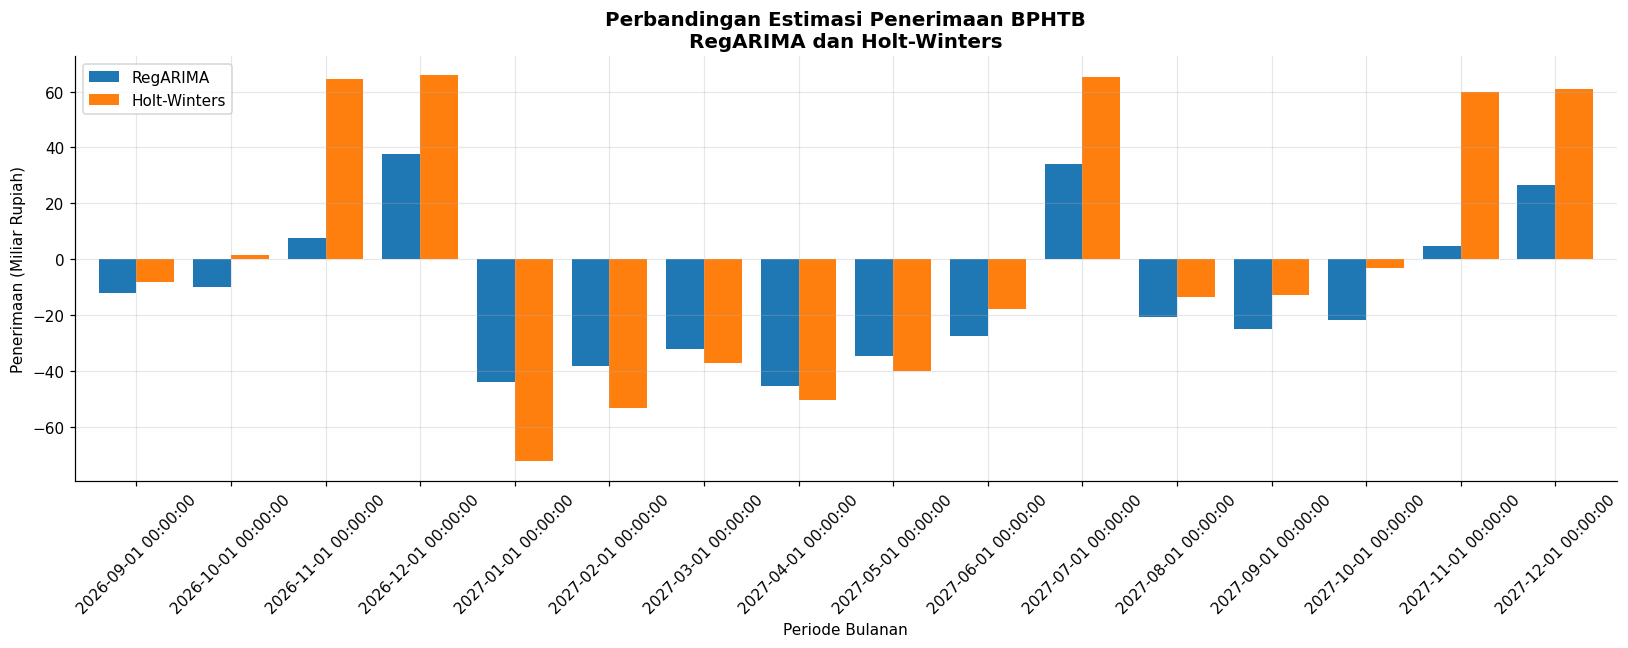

In [23]:
forecast_plot = hasil_forecast[
    ["RegARIMA", "Holt-Winters"]
].copy()

forecast_plot = forecast_plot / 1_000_000_000

forecast_plot.plot(
    kind="bar",
    figsize=(15, 6),
    width=0.8
)

plt.title(
    "Perbandingan Estimasi Penerimaan BPHTB\n"
    "RegARIMA dan Holt-Winters",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel("Periode Bulanan")
plt.ylabel("Penerimaan (Miliar Rupiah)")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()